In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpy.random as nr
import jax
import scipy
from gestimators import BF
from IMH2 import IndMH
import matplotlib.pyplot as plt
from gdistribution import gprior, mix_normal
import math

In [2]:
# def load_data():
#         file = '/home/ranbot/optionpricing/data/ripley.mat'
#         mat = scipy.io.loadmat(file)
#         data = mat['X']
#         inputs = data[:, 0:-1]
#         print(inputs.shape)
#         outputs = data[:, -1]
#         return inputs, outputs

# input, output = load_data()

# n_predata = 50
# def gen_data():
#     X = nr.multivariate_normal(np.zeros(4), np.eye(4), n_predata)
#     y = np.zeros(n_predata)
#     for i in range(n_predata):
#         y[i] = nr.normal(4*X[i,2] + 4*X[i,3], 2.5)
#     #write to file
#     df = pd.DataFrame(X)
#     df['y'] = y
#     df.to_csv('data.csv', index=False)
#     return X, y

# gen_data()

In [3]:
#read from file
def read_data():
    df = pd.read_csv('data.csv')
    X = df.values[:, 0:-1]
    y = df.values[:, -1]
    return X, y



L = [[0],[1],[2],[3],[0,1],[0,2],[0,3],[1,2],[1,3],[2,3],[0,1,2],[0,1,3],[0,2,3],[1,2,3],[0,1,2,3]]
names = []
for i in range(15):
    strs = ''
    inst = L[i]
    leni = len(inst)
    for j in range(leni):
        strs += str(inst[j]+1)
    strs = "x" + strs + '.npy'
    names.append(strs)
print(names)


['x1.npy', 'x2.npy', 'x3.npy', 'x4.npy', 'x12.npy', 'x13.npy', 'x14.npy', 'x23.npy', 'x24.npy', 'x34.npy', 'x123.npy', 'x124.npy', 'x134.npy', 'x234.npy', 'x1234.npy']


In [4]:
Truth = []
LiIMCV = []
LiCMC = []
VRFt = []
for i in range(15):
    w = nr.beta(1,1,10000)
    g = w/(1-w)
    print(names[i])
    input, output = read_data()
    input = input[:, L[i]]
    try: 
        input.shape[1]
    except:
        input = input[:,np.newaxis]
    dim = input.shape[1]
    N = input.shape[0]
    s = 2.5
    cov0 = np.linalg.inv(input.T @ input)

    def true_mean():
        const = (2*np.pi)**(-N/2)*s**(-N)*np.exp(-0.5*s**(-2)*np.sum(output**2))
        t = np.sum(output[:, np.newaxis]*input, axis=0)
        expcoef = 0.5*s**(-2)*(t.T @ cov0 @ t)
        def integrant(x):
            return const*np.exp(expcoef * x / (x+s**2)) *(1+x/s**2)**(-dim/2) * (1+x)**(-2)
        return scipy.integrate.quad(integrant, 0, np.inf)[0]

    tm = true_mean()
    Truth.append(tm)
    print(tm)
    nc = 4
    tar = gprior(dim)
    tar.set_parameters(cov0,input, g)
    pro = mix_normal(dim)
    a = tar.sampler(1000)
    try: 
        weights = np.load(names[i])[0]
        gs = np.load(names[i])[1]
        covs = np.array([gs[i]*cov0 for i in range(nc)])
    except:
        pro.em_algorithm(a,nc,input,3001)
        weights = pro.weights
        gs = pro.gs
        covs = np.array([gs[i]*cov0 for i in range(nc)])
        np.save(names[i], [weights, gs])

    # Itrnum = 1100
    # sample_size = 1000
    # target = 'gprior'
    # proposal = 'mix_normal'

    # epoch = 100
    # cmc_mean = []
    # imhcv_mean = []
    # print("start")

    # for i in range(epoch):
    #     w = nr.beta(1,1,10000)
    #     g = w/(1-w)
    #     estcmc = BF(sample_size, weights, cov0, gs, input, output)
    #     tar = gprior(dim)
    #     tar.set_parameters(cov0, input, g)
    #     MyIM = IndMH(Itrnum, dim, target, proposal)
    #     est = BF(sample_size, weights, cov0, gs, input, output)
    #     MyIM.set_distribution_parameters(cov0, nc, weights, covs, input, g, gs)
    #     data = MyIM.IMH()
    #     est.sample_loader(data[0],data[1],data[2])
    #     m,v= est.IMCV0()
    #     imhcv_mean.append(m)
    #     datacmc = tar.sampler(sample_size)
    #     estcmc.cmc_loader(datacmc)
    #     mc,vc = estcmc.CMC()
    #     cmc_mean.append(mc)

    # var_imhcv = np.array(imhcv_mean).var()
    # var_cmc = np.array(cmc_mean).var()
    # print('STD_IMCV:', np.sqrt(var_imhcv))
    # print('STD_CMC:', np.sqrt(var_cmc))
    # mean_imhcv = np.array(imhcv_mean).mean()
    # mean_cmc = np.array(cmc_mean).mean()
    # error_imhcv = mean_imhcv - tm
    # error_cmc = mean_cmc - tm
    # print('True mean:',tm)
    # print('IMCV:',mean_imhcv,'error:', np.abs(error_imhcv))
    # print('CMC:',mean_cmc, 'error:',np.abs(error_cmc))
    # # print('MSECMC:',msecmc)
    # LiIMCV.append(mean_imhcv)
    # LiCMC.append(mean_cmc)
    # VRFt.append(var_cmc/var_imhcv)
    # print('VRF:',var_cmc/var_imhcv)

x1.npy
3.451032839159709e-84


x2.npy
1.5346788637644075e-82
x3.npy
2.5870275332426055e-74
x4.npy
6.198210673805663e-63
x12.npy
1.3265878452954582e-82
x13.npy
9.466293632415017e-75
x14.npy
9.074131131677923e-64
x23.npy
7.414326092518034e-74
x24.npy
1.4878767469048829e-61
x34.npy
2.9932102785461202e-53
x123.npy
3.996871597750754e-74
x124.npy
2.755899019802248e-62
x134.npy
4.2313636021400844e-54
x234.npy
1.504962484248503e-53
x1234.npy
2.5660630466039193e-54


In [5]:
# Truth = np.array(Truth)
# LiIMCV = np.array(LiIMCV)
# LiCMC = np.array(LiCMC)
# VRFt = np.array(VRFt)
# BF_truth = Truth / Truth[0]
# BF_imcv = LiIMCV / LiIMCV[0]
# BF_cmc = LiCMC / LiCMC[0]
# for i in range(15):
#     print('$X_{', names[i][1:-4] ,'}$', '&',format(LiCMC[i],'.2e'), ' & ' ,format(LiIMCV[i],'.2e') ,' & ' , format(Truth[i],'.2e') , ' & ',np.round(VRFt[i],2), ' & ' , format(BF_cmc[i],'.2') ,  ' & ' , format(BF_imcv[i],'.2') ,  ' & ' , format(BF_truth[i],'.2') , '\\\\')

In [6]:

    # 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15
A = [[0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0], #1
     [0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0], #2
     [0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0], #3
     [0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0], #4
     [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0], #5
     [1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0], #6
     [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0], #7
     [0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0], #8
     [0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0], #9
     [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0], #10
     [0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1], #11
     [0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1], #12
     [0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1], #13
     [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1], #14
     [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0]] #15

A = np.array(A)
transp = np.sum(A, axis=1)
choices = np.array([i for i in range(15)])
input0, output = read_data()

In [7]:
nitrs = 20000
init = 0
state = np.array([init,init,init])
sample_size = 10
Itrnum = sample_size+5
nc = 4
target = 'gprior'
proposal = 'mix_normal'

def est_lik(state, input0):
    inputs = input0[:, L[state]]
    try:
        inputs.shape[1]
    except:
        inputs = inputs[:,np.newaxis]
    dim = inputs.shape[1]
    cov0 = np.linalg.inv(inputs.T @ inputs)
    weights = np.load(names[state])[0]
    gs = np.load(names[state])[1]
    covs = np.array([gs[i]*cov0 for i in range(nc)])
    w = nr.beta(1,1,sample_size)
    g = w/(1-w)
    estcmc = BF(sample_size, weights, cov0, gs, inputs, output)
    tar = gprior(dim)
    tar.set_parameters(cov0, inputs, g)
    MyIM = IndMH(Itrnum, dim, target, proposal)
    est = BF(sample_size, weights, cov0, gs, inputs, output)
    MyIM.set_distribution_parameters(cov0, nc, weights, covs, inputs, g, gs)
    data = MyIM.IMH()
    est.sample_loader(data[0],data[1],data[2])
    m,v= est.IMCV0()
    # m0,v0 = est.IM()
    datacmc = tar.sampler(sample_size)
    estcmc.cmc_loader(datacmc)
    mc,vc = estcmc.CMC()
    return m,mc

tar_lik = np.array([est_lik(state[i],input0)[i] for i in range(2)])
pro_lik = np.array([1/transp[state[i]] for i in range(2)])
pmap = np.zeros((15,nitrs+1,2))
print(pmap.shape)  
for i in range(nitrs):
    if (i+1)%100 == 0:
        print((i+1)/nitrs *100, '%', ' finished')
    for j in range(2):
        proposed = np.random.choice(choices, p=A[state[j]]/np.sum(A[state[j]]))
        sample = np.random.uniform(0.0, 1.0, 1)
        tar_lik_now = est_lik(proposed,input0)[j]
        ratio_tar = tar_lik_now/tar_lik[j]
        ratio_pro = transp[proposed]*pro_lik[j]
        ratio = min(1, ratio_tar*ratio_pro)
        if sample <= ratio:
            state[j] = proposed
            tar_lik[j] = tar_lik_now
            pro_lik[j] = 1/transp[state[j]]
        pmap[:,i+1,j] = pmap[:,i,j]
        pmap[state[j],i+1,j] += 1

pmap = pmap/nitrs



(15, 20001, 2)
0.5 %  finished
1.0 %  finished
1.5 %  finished
2.0 %  finished
2.5 %  finished
3.0 %  finished
3.5000000000000004 %  finished
4.0 %  finished
4.5 %  finished
5.0 %  finished
5.5 %  finished
6.0 %  finished
6.5 %  finished
7.000000000000001 %  finished
7.5 %  finished
8.0 %  finished
8.5 %  finished
9.0 %  finished
9.5 %  finished
10.0 %  finished
10.5 %  finished
11.0 %  finished
11.5 %  finished
12.0 %  finished
12.5 %  finished
13.0 %  finished
13.5 %  finished
14.000000000000002 %  finished
14.499999999999998 %  finished
15.0 %  finished
15.5 %  finished
16.0 %  finished
16.5 %  finished
17.0 %  finished
17.5 %  finished
18.0 %  finished
18.5 %  finished
19.0 %  finished
19.5 %  finished
20.0 %  finished
20.5 %  finished
21.0 %  finished
21.5 %  finished
22.0 %  finished
22.5 %  finished
23.0 %  finished
23.5 %  finished
24.0 %  finished
24.5 %  finished
25.0 %  finished
25.5 %  finished
26.0 %  finished
26.5 %  finished
27.0 %  finished
27.500000000000004 %  finishe

[[0.0000e+00 0.0000e+00]
 [0.0000e+00 0.0000e+00]
 [0.0000e+00 5.0000e-05]
 [5.0000e-05 5.0000e-05]
 [0.0000e+00 0.0000e+00]
 [0.0000e+00 5.0000e-05]
 [5.0000e-05 0.0000e+00]
 [0.0000e+00 0.0000e+00]
 [1.5000e-04 1.0000e-04]
 [5.5945e-01 8.8720e-01]
 [0.0000e+00 0.0000e+00]
 [5.0000e-05 0.0000e+00]
 [1.2240e-01 5.0650e-02]
 [3.0705e-01 3.6350e-02]
 [1.0800e-02 2.5550e-02]]


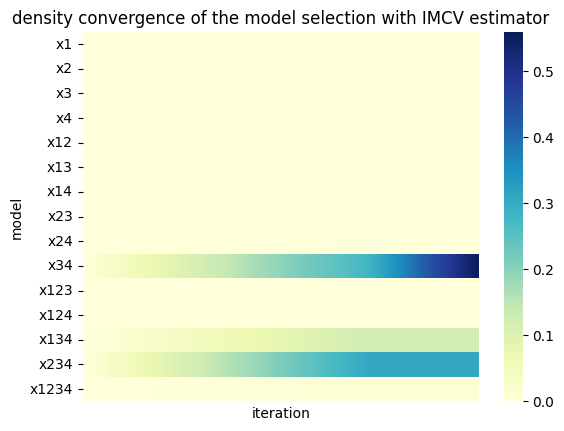

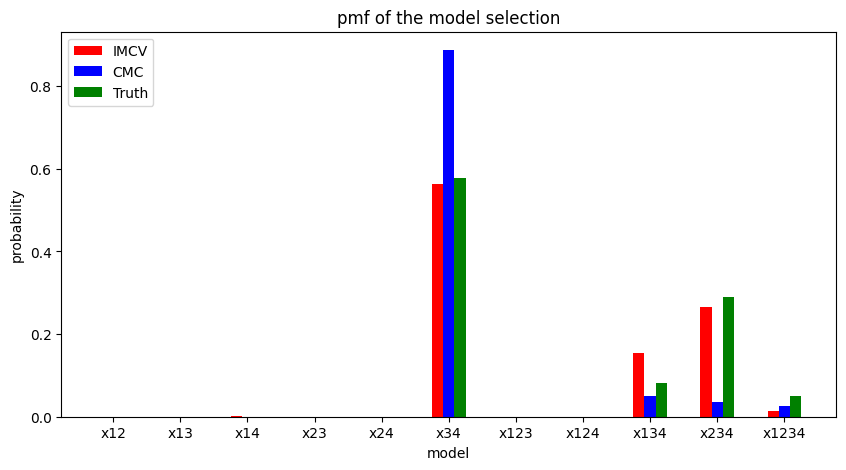

In [8]:
import seaborn as sns
print(pmap[:,-1,:])
names_new = [names[i][:-4] for i in range(15)]
sns.heatmap(pmap[:,:,0], cmap="YlGnBu", yticklabels=names_new, xticklabels=False)
plt.title('density convergence of the model selection with IMCV estimator')
plt.xlabel('iteration')
plt.ylabel('model')
plt.show()

labels = ['x1', 'x2', 'x3', 'x4', 'x12', 'x13', 'x14', 'x23', 'x24', 'x34', 'x123', 'x124', 'x134', 'x234', 'x1234']
labels0 = ['x12', 'x13', 'x14', 'x23', 'x24', 'x34', 'x123', 'x124', 'x134', 'x234', 'x1234']
pmf_imcv = pmap[:,-1,0]
pmf_cmc = pmap[:,-1,1]
pmf_t = Truth/np.sum(Truth)
X = np.arange(11)*1.5
width = 0.25
plt.figure(figsize=(10,5))
pmf_imcv = np.load('imcv.npy')
plt.bar(X-width,pmf_imcv[4:],width,color='r')
# plt.bar(X-0.5*width,pmf_im,width,color='g')
plt.bar(X,pmf_cmc[4:],width,color='b')
plt.bar(X+width,pmf_t[4:],width,color='g')
plt.xticks(X, labels0)
plt.legend(['IMCV', 'CMC', 'Truth'], loc='upper left')
plt.title('pmf of the model selection')
plt.xlabel('model')
plt.ylabel('probability')


plt.show()